In [2]:
!pip install -q nltk gensim scikit-learn numpy pandas matplotlib seaborn

In [3]:
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import wordnet
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from gensim.models import Word2Vec
import gensim.downloader as api

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

print("Libraries imported successfully!")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [4]:
word_pairs = [
    ("ocean", "sea"),
    ("coral", "reef"),
    ("whale", "dolphin"),
    ("pollution", "contamination"),
    ("fish", "shark"),
    ("plastic", "waste"),
    ("marine", "aquatic"),
    ("conservation", "protection"),
    ("warm", "cold"),
    ("turtle", "reptile")
]

documents = [
    "Marine biologists study ocean ecosystems and aquatic organisms.",
    "Coral reefs provide shelter and food for many marine species.",
    "Plastic pollution damages oceans and threatens marine animals.",
    "Sea turtles and dolphins are important parts of ocean biodiversity.",
    "Scientists monitor water temperature and ocean currents.",
    "Marine conservation protects wildlife and preserves aquatic habitats."
]

print("Word pairs:", len(word_pairs))
print("Documents:", len(documents))

Word pairs: 10
Documents: 6


In [5]:
def wordnet_similarity(word1, word2):

    synsets1 = wordnet.synsets(word1, pos=wordnet.NOUN)
    synsets2 = wordnet.synsets(word2, pos=wordnet.NOUN)

    if not synsets1 or not synsets2:
        return None, None, None

    path_scores = []
    wup_scores = []
    lch_scores = []

    for s1 in synsets1:
        for s2 in synsets2:

            path = s1.path_similarity(s2)
            wup = s1.wup_similarity(s2)
            lch = s1.lch_similarity(s2)

            if path is not None:
                path_scores.append(path)

            if wup is not None:
                wup_scores.append(wup)

            if lch is not None:
                lch_scores.append(lch)

    return (
        max(path_scores) if path_scores else None,
        max(wup_scores) if wup_scores else None,
        max(lch_scores) if lch_scores else None
    )


wordnet_results = []

for w1, w2 in word_pairs:

    path, wup, lch = wordnet_similarity(w1, w2)

    wordnet_results.append({
        "Word 1": w1,
        "Word 2": w2,
        "Path": path,
        "WUP": wup,
        "LCH": lch
    })

wordnet_df = pd.DataFrame(wordnet_results)

display(wordnet_df)

,Word 1,Word 2,Path,WUP,LCH
0,ocean,sea,1.000000,1.000000,3.637586
1,coral,reef,0.090909,0.444444,1.239691
2,whale,dolphin,0.333333,0.933333,2.538974
3,pollution,contamination,1.000000,1.000000,3.637586
4,fish,shark,0.250000,0.880000,2.251292
5,plastic,waste,0.166667,0.545455,1.845827
6,marine,aquatic,0.125000,0.631579,1.558145
7,conservation,protection,0.333333,0.875000,2.538974
8,warm,cold,NaN,NaN,NaN
9,turtle,reptile,0.250000,0.869565,2.251292


In [6]:
corpus = [
    "ocean marine sea water aquatic ecosystem",
    "coral reef marine species ocean habitat",
    "whale dolphin shark fish marine animals",
    "plastic pollution waste ocean contamination",
    "marine conservation wildlife protection",
    "sea turtle aquatic animal biodiversity",
    "ocean currents water temperature climate",
    "coral reefs provide shelter for fish",
    "scientists study marine ecosystems",
    "pollution threatens ocean biodiversity",
    "aquatic habitats support marine wildlife",
    "conservation protects ocean species"
]

tokenized_corpus = [
    sentence.lower().split()
    for sentence in corpus
]

w2v_model = Word2Vec(
    sentences=tokenized_corpus,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=200,
    seed=42
)

print("Word2Vec model trained successfully!")

Word2Vec model trained successfully!


In [7]:
w2v_results = []

for w1, w2 in word_pairs:

    if w1 in w2v_model.wv and w2 in w2v_model.wv:

        score = w2v_model.wv.similarity(w1, w2)

    else:
        score = None

    w2v_results.append(score)

wordnet_df["Word2Vec"] = w2v_results

display(wordnet_df)

,Word 1,Word 2,Path,WUP,LCH,Word2Vec
0,ocean,sea,1.000000,1.000000,3.637586,0.092010
1,coral,reef,0.090909,0.444444,1.239691,0.084915
2,whale,dolphin,0.333333,0.933333,2.538974,0.126017
3,pollution,contamination,1.000000,1.000000,3.637586,-0.051995
4,fish,shark,0.250000,0.880000,2.251292,0.342796
5,plastic,waste,0.166667,0.545455,1.845827,0.016540
6,marine,aquatic,0.125000,0.631579,1.558145,0.331374
7,conservation,protection,0.333333,0.875000,2.538974,-0.045127
8,warm,cold,NaN,NaN,NaN,NaN
9,turtle,reptile,0.250000,0.869565,2.251292,NaN


In [8]:
glove_model = api.load("glove-wiki-gigaword-50")

print("GloVe model loaded successfully!")

[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe model loaded successfully!


In [9]:
glove_results = []

for w1, w2 in word_pairs:

    if w1 in glove_model and w2 in glove_model:

        score = glove_model.similarity(w1, w2)

    else:
        score = None

    glove_results.append(score)

wordnet_df["GloVe"] = glove_results

display(wordnet_df)

,Word 1,Word 2,Path,WUP,LCH,Word2Vec,GloVe
0,ocean,sea,1.000000,1.000000,3.637586,0.092010,0.881165
1,coral,reef,0.090909,0.444444,1.239691,0.084915,0.773911
2,whale,dolphin,0.333333,0.933333,2.538974,0.126017,0.813620
3,pollution,contamination,1.000000,1.000000,3.637586,-0.051995,0.694991
4,fish,shark,0.250000,0.880000,2.251292,0.342796,0.708046
5,plastic,waste,0.166667,0.545455,1.845827,0.016540,0.536103
6,marine,aquatic,0.125000,0.631579,1.558145,0.331374,0.560855
7,conservation,protection,0.333333,0.875000,2.538974,-0.045127,0.711724
8,warm,cold,NaN,NaN,NaN,NaN,0.791836
9,turtle,reptile,0.250000,0.869565,2.251292,NaN,0.661694


In [10]:
print("SEMANTIC SIMILARITY COMPARISON")

display(
    wordnet_df.round(4)
)

SEMANTIC SIMILARITY COMPARISON


,Word 1,Word 2,Path,WUP,LCH,Word2Vec,GloVe
0,ocean,sea,1.0000,1.0000,3.6376,0.0920,0.8812
1,coral,reef,0.0909,0.4444,1.2397,0.0849,0.7739
2,whale,dolphin,0.3333,0.9333,2.5390,0.1260,0.8136
3,pollution,contamination,1.0000,1.0000,3.6376,-0.0520,0.6950
4,fish,shark,0.2500,0.8800,2.2513,0.3428,0.7080
5,plastic,waste,0.1667,0.5455,1.8458,0.0165,0.5361
6,marine,aquatic,0.1250,0.6316,1.5581,0.3314,0.5609
7,conservation,protection,0.3333,0.8750,2.5390,-0.0451,0.7117
8,warm,cold,NaN,NaN,NaN,NaN,0.7918
9,turtle,reptile,0.2500,0.8696,2.2513,NaN,0.6617


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [11]:
tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(documents)

tfidf_similarity = cosine_similarity(tfidf_matrix)

print("TF-IDF Document Similarity Matrix")

tfidf_df = pd.DataFrame(
    tfidf_similarity,
    index=[f"D{i+1}" for i in range(len(documents))],
    columns=[f"D{i+1}" for i in range(len(documents))]
)

display(tfidf_df.round(3))

TF-IDF Document Similarity Matrix


,D1,D2,D3,D4,D5,D6
D1,1.000,0.079,0.090,0.096,0.119,0.205
D2,0.079,1.000,0.073,0.023,0.028,0.075
D3,0.090,0.073,1.000,0.026,0.032,0.086
D4,0.096,0.023,0.026,1.000,0.096,0.027
D5,0.119,0.028,0.032,0.096,1.000,0.033
D6,0.205,0.075,0.086,0.027,0.033,1.000


In [12]:
def document_vector(document, model):

    words = document.lower().split()

    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


doc_vectors = np.array([
    document_vector(doc, w2v_model)
    for doc in documents
])

w2v_doc_similarity = cosine_similarity(doc_vectors)

w2v_doc_df = pd.DataFrame(
    w2v_doc_similarity,
    index=[f"D{i+1}" for i in range(len(documents))],
    columns=[f"D{i+1}" for i in range(len(documents))]
)

print("Word2Vec Document Similarity Matrix")

display(w2v_doc_df.round(3))

Word2Vec Document Similarity Matrix


,D1,D2,D3,D4,D5,D6
D1,1.000,0.664,0.547,0.637,0.661,0.750
D2,0.664,1.000,0.642,0.522,0.528,0.595
D3,0.547,0.642,1.000,0.420,0.457,0.516
D4,0.637,0.522,0.420,1.000,0.699,0.477
D5,0.661,0.528,0.457,0.699,1.000,0.506
D6,0.750,0.595,0.516,0.477,0.506,1.000


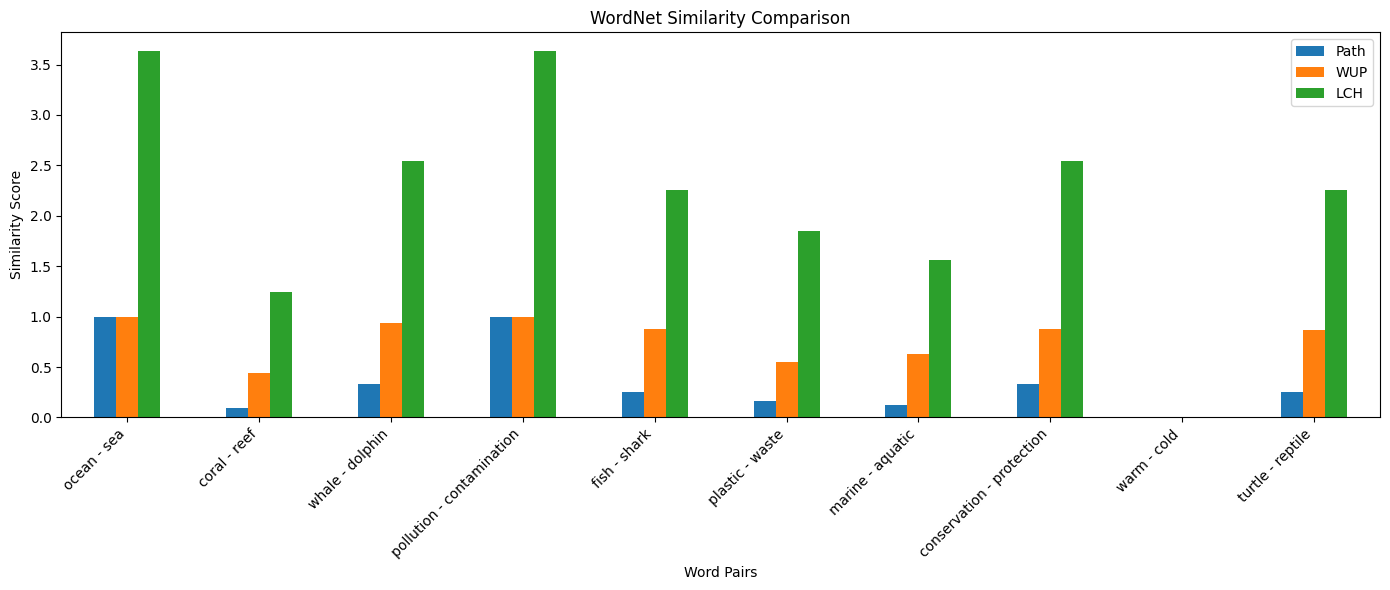

In [13]:
wordnet_df.set_index(
    wordnet_df["Word 1"] + " - " + wordnet_df["Word 2"]
)[["Path", "WUP", "LCH"]].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("WordNet Similarity Comparison")
plt.xlabel("Word Pairs")
plt.ylabel("Similarity Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

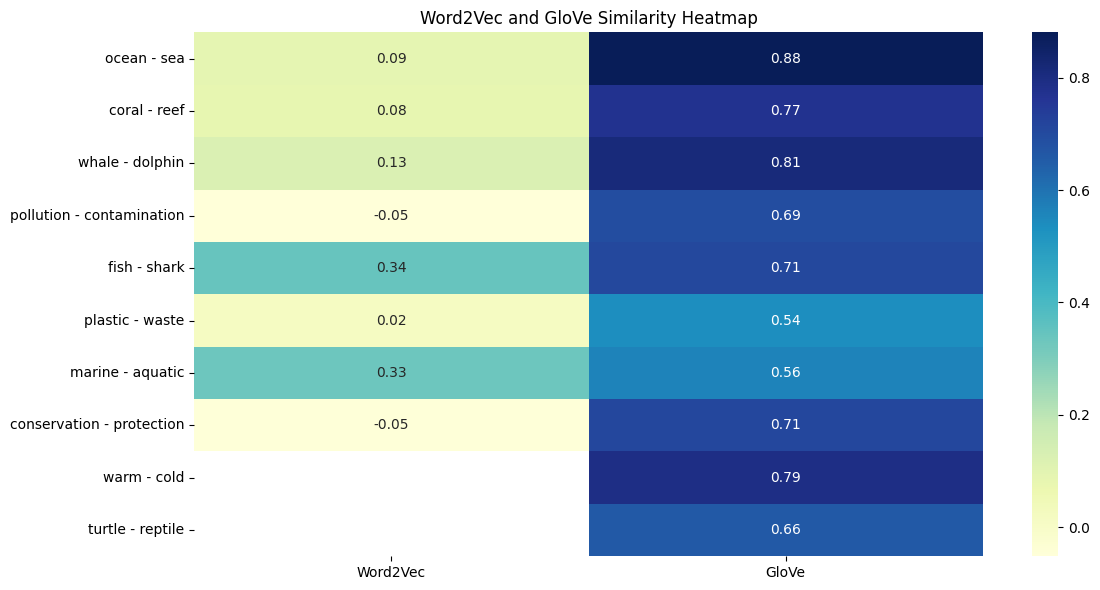

In [14]:
embedding_df = wordnet_df.set_index(
    wordnet_df["Word 1"] + " - " + wordnet_df["Word 2"]
)[["Word2Vec", "GloVe"]]

plt.figure(figsize=(12, 6))

sns.heatmap(
    embedding_df,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Word2Vec and GloVe Similarity Heatmap")
plt.tight_layout()
plt.show()

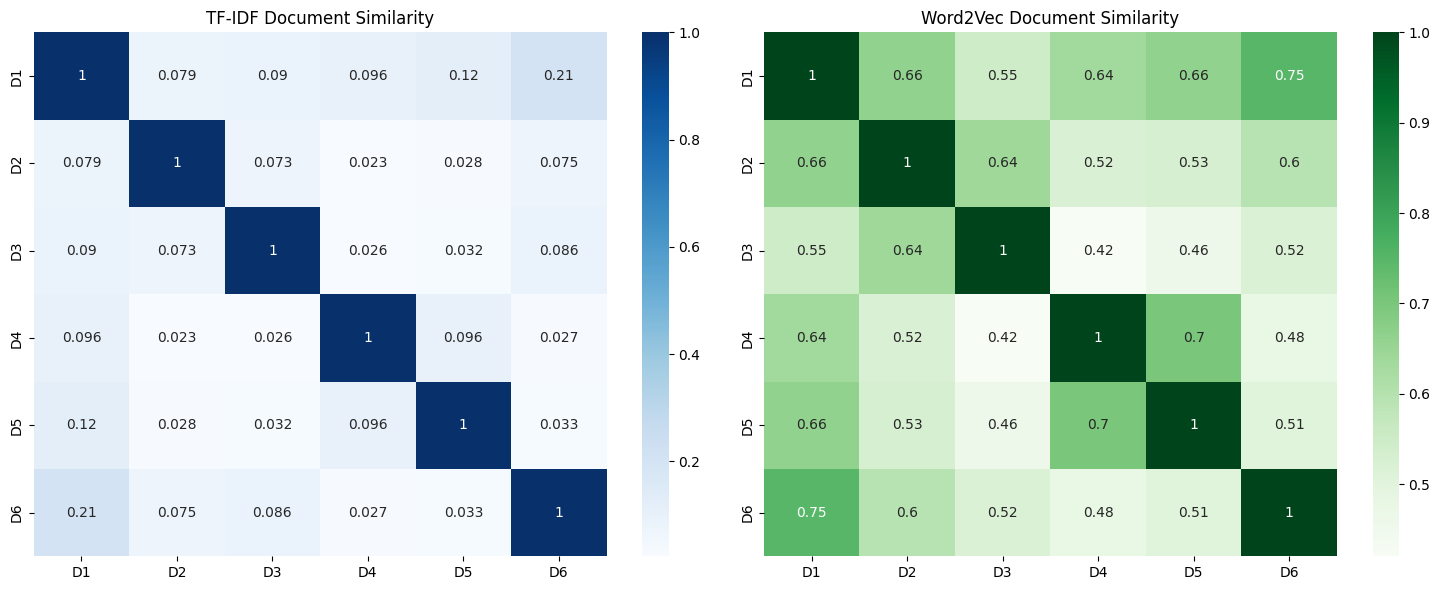

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    tfidf_df,
    annot=True,
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("TF-IDF Document Similarity")

sns.heatmap(
    w2v_doc_df,
    annot=True,
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Word2Vec Document Similarity")

plt.tight_layout()
plt.show()

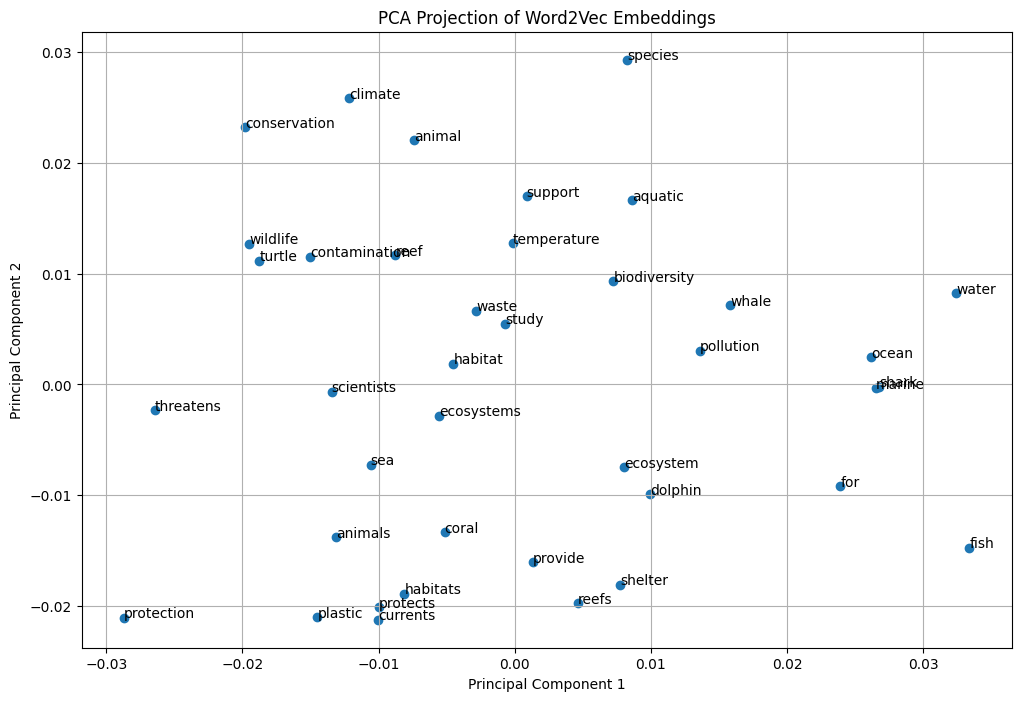

In [16]:
words = list(w2v_model.wv.index_to_key)

vectors = np.array([
    w2v_model.wv[word]
    for word in words
])

pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(12, 8))

plt.scatter(
    reduced_vectors[:, 0],
    reduced_vectors[:, 1]
)

for i, word in enumerate(words):

    plt.annotate(
        word,
        (reduced_vectors[i, 0], reduced_vectors[i, 1])
    )

plt.title("PCA Projection of Word2Vec Embeddings")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

In [17]:
print("EXPERIMENT 8 COMPLETED SUCCESSFULLY")

print("WordNet Similarity:")
display(wordnet_df)

print("TF-IDF Document Similarity:")
display(tfidf_df)

print("Word2Vec Document Similarity:")
display(w2v_doc_df)

EXPERIMENT 8 COMPLETED SUCCESSFULLY
WordNet Similarity:


,Word 1,Word 2,Path,WUP,LCH,Word2Vec,GloVe
0,ocean,sea,1.000000,1.000000,3.637586,0.092010,0.881165
1,coral,reef,0.090909,0.444444,1.239691,0.084915,0.773911
2,whale,dolphin,0.333333,0.933333,2.538974,0.126017,0.813620
3,pollution,contamination,1.000000,1.000000,3.637586,-0.051995,0.694991
4,fish,shark,0.250000,0.880000,2.251292,0.342796,0.708046
5,plastic,waste,0.166667,0.545455,1.845827,0.016540,0.536103
6,marine,aquatic,0.125000,0.631579,1.558145,0.331374,0.560855
7,conservation,protection,0.333333,0.875000,2.538974,-0.045127,0.711724
8,warm,cold,NaN,NaN,NaN,NaN,0.791836
9,turtle,reptile,0.250000,0.869565,2.251292,NaN,0.661694


TF-IDF Document Similarity:


,D1,D2,D3,D4,D5,D6
D1,1.000000,0.078642,0.089851,0.096169,0.118896,0.205096
D2,0.078642,1.000000,0.073372,0.022879,0.028286,0.075279
D3,0.089851,0.073372,1.000000,0.026140,0.032318,0.086009
D4,0.096169,0.022879,0.026140,1.000000,0.096375,0.026820
D5,0.118896,0.028286,0.032318,0.096375,1.000000,0.033158
D6,0.205096,0.075279,0.086009,0.026820,0.033158,1.000000


Word2Vec Document Similarity:


,D1,D2,D3,D4,D5,D6
D1,1.000000,0.664319,0.546875,0.636561,0.661263,0.749576
D2,0.664319,1.000000,0.641524,0.521512,0.527549,0.595056
D3,0.546875,0.641524,1.000000,0.420335,0.456854,0.515658
D4,0.636561,0.521512,0.420335,1.000000,0.699191,0.476916
D5,0.661263,0.527549,0.456854,0.699191,1.000000,0.506306
D6,0.749576,0.595056,0.515658,0.476916,0.506306,1.000000
